# Checkpoint Week 1 — KNN &amp; Naive Bayes

Vul alle cellen in en push dit bestand naar je repo. De automatische checks (GitHub Actions) voeren dit notebook uit en controleren of alle **variabelen met de gevraagde namen** bestaan en correct zijn.

**BELANGRIJK**: gebruik exact de genoemde variabelennamen (accuracy_iris, mse_mall, spam_given_money, ...), anders faalt de controle.

---
# KNN

## Oefening 1 — Eigen KNN-implementatie

Implementeer KNNClassifier. De constructor krijgt k mee; fit bewaart de trainingsdata; predict geeft voor elk punt het meerderheidslabel van de k dichtste buren (Euclidische afstand).

In [ ]:
import numpy as np

class KNNClassifier:
    def __init__(self, k=3):
        self.k = k
        self.X_train = None
        self.y_train = None

    def fit(self, X, y):
        self.X_train = np.asarray(X, dtype=float)
        self.y_train = np.asarray(y)
        return self

    def predict(self, X):
        X = np.asarray(X, dtype=float)
        preds = []
        for x in X:
            dists = np.sqrt(((self.X_train - x) ** 2).sum(axis=1))
            idx = np.argsort(dists)[:self.k]
            labels, counts = np.unique(self.y_train[idx], return_counts=True)
            preds.append(labels[np.argmax(counts)])
        return np.array(preds)

### Extra oefening — KNN met euclidean_distance (scaffolding)

Gebruik deze versie om stap voor stap de Euclidische afstand te implementeren.

In [ ]:
import numpy as np

class KNNClassifierScaffold:
    def __init__(self, k=3):
        self.k = k
        self.X_train = None
        self.y_train = None

    def fit(self, X, y):
        #todo
        self.X_train = X
        self.y_train = y

    def euclidean_distance(self, x1, x2):
        return np.sqrt(np.sum((x1 - x2)**2))

    def predict(self, X):
        predictions = [self._predict(x) for x in X]
        return np.array(predictions)

    def _predict(self, x):
        #todo: 1 item voorspellen
        # bereken voor X de afstand met alle items van X_train
        # sorteren volgens van klein naar groot volgens die afstand
        # de eerste k labels (y data): neem daarvan het gemiddelde
        # gebruik np.argsort, np.mean
        
        distances = []
        for x_train in self.X_train:
            distances.append(self.euclidean_distance(x, x_train))
        
        gestorteerd = np.argsort(distances)
        k_indices = gestorteerd[:self.k]
        
        return np.mean(self.y_train[k_indices])
            

        
        
                
# Sample dataset - house prices
X_train = np.array([
    [0, 0, 1000, 2, 1],
    [1, 1, 1500, 3, 2],
    [2, 2, 1200, 2, 1],
    [3, 3, 1800, 4, 2],
    [4, 4, 2000, 3, 2]
])
y_train = np.array([200000, 250000, 220000, 280000, 300000])
X_test = np.array([
    [5, 5, 1600, 3, 1],
    [2, 3, 1300, 2, 1]
])

knn_scaffold = KNNClassifierScaffold(k=3)
knn_scaffold.fit(X_train[:, 1:], y_train)
predictions = knn_scaffold.predict(X_test[:, 1:])
print("Predicted house prices:", predictions)

## Oefening 2 — Iris met sklearn-KNN

- Laad de iris-dataset, splits in train/test (test_size=0.25, random_state=42).
- **Normaliseer** met een StandardScaler (fit op train alleen!).
- Train een KNeighborsClassifier(n_neighbors=5).
- Sla de voorspellingen op in y_pred_iris en de **accuracy op de testset** in accuracy_iris (float).

In [ ]:
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score

X, y = load_iris(return_X_y=True)

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=42)

scaler = StandardScaler().fit(X_train)

X_train_scaled = scaler.transform(X_train)
X_test_scaled = scaler.transform(X_test)

knn = KNeighborsClassifier(n_neighbors=5).fit(X_train_scaled, y_train)
y_pred_iris = knn.predict(X_test_scaled)
accuracy_iris = accuracy_score(y_test, y_pred_iris)
print(accuracy_iris)

**Vraag (antwoord in antwoord_normaliseren)**: Waarom moet je de features normaliseren vóór KNN? Kies A, B, C of D:
- A: Omdat KNN alleen met integers werkt
- B: Omdat afstanden anders vertekend worden door schaalverschillen tussen features
- C: Omdat accuracy dan altijd 100% wordt
- D: Omdat sklearn dat vereist voor alle modellen

In [ ]:
antwoord_normaliseren = ""

### Iris — stap voor stap (extra scaffolding)

Werk deze cellen uit om het effect van de StandardScaler te onderzoeken.

In [ ]:
# Dataset inladen
iris = load_iris()
X = iris.data
y = iris.target
print(iris.keys())
iris.target_names

In [ ]:
# zoek op hoe je data kan train-test splitten

In [ ]:
# Gebruik een standardscaler op de X_train, X_test data

In [ ]:
# Gebruik een KNeighborsclassifier van de sklearn library. Fit deze. Maak voorspellingen.

In [ ]:
# Bereken de accuracy.

In [ ]:
# maak een classificatie report

## Oefening 3 — Mall Customers (one-hot + regressie)

- Laad data/Mall_Customers.csv (staat in dezelfde map als dit notebook).
- One-hot encode Gender, voeg samen met Age en Annual Income (k$).
- Doelvariabele: Spending Score (1-100) : gebruik een KNeighborsRegressor(n_neighbors=5) met train/test split (test_size=0.25, random_state=42).
- Sla de test-voorspellingen op in y_pred_mall en de **MSE** in mse_mall (float).

In [ ]:
import pandas as pd
from sklearn.preprocessing import OneHotEncoder
from sklearn.neighbors import KNeighborsRegressor
from sklearn.metrics import mean_squared_error


df = pd.read_csv('data/Mall_Customers.csv')
# encoderr = OneHotEncoder(drop='first', sparse_output=False)

df.head()






In [85]:
encoder = OneHotEncoder(drop='first', sparse_output=False) #zet gender naar binary
gender_encoder = encoder.fit_transform(df[['Gender']]) #fit=(leer van data) en transform=(voert het uit)

X_mall = pd.DataFrame(gender_encoder, columns=['gender_encoded'])
X_mall[['Age', 'Annual Income (k$)']] = df[['Age', 'Annual Income (k$)']].values

X_mall.head()

y = df['Spending Score (1-100)']

X_train, X_test, y_train, y_test = train_test_split(X_mall, y, test_size=0.25, random_state=42)

reg = KNeighborsRegressor(n_neighbors=5).fit(X_train, y_train)

y_pred_mall = reg.predict(X_test)

mse_mall = mean_squared_error(y_test, y_pred_mall)

print(f'{np.sqrt(mse_mall)}')


19.839858870465786


In [ ]:
vergelijk = pd.DataFrame({'echt': y_test.values, 'voorspeld': y_pred_mall})
vergelijk['fout'] = vergelijk['echt'] - vergelijk['voorspeld']
print(vergelijk)

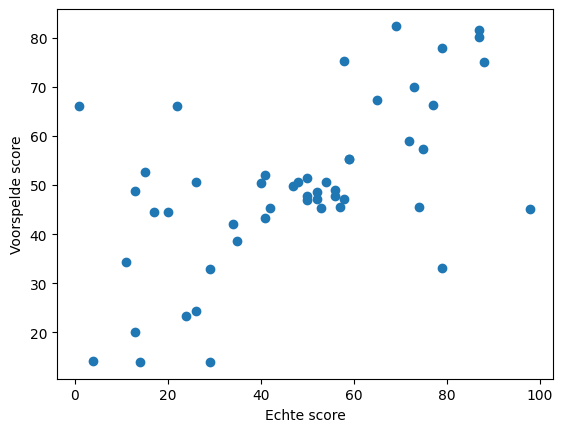

In [84]:
import matplotlib.pyplot as plt


plt.scatter(y_test, y_pred_mall)
plt.xlabel('Echte score')
plt.ylabel('Voorspelde score')
plt.show()

**Vraag (antwoord in antwoord_k_kiezen)**: Hoe kies je K het best? Kies A, B, C of D:
- A: Altijd K=1
- B: Zomaar op het gevoel
- C: Via cross-validatie
- D: K moet altijd gelijk zijn aan het aantal klassen

In [ ]:
antwoord_k_kiezen = "c"

### Mall customers — stap voor stap (extra scaffolding)

Bekijk de data van de Mall_customers.csv - laad deze in en bekijk de kolommen. Pas hier KNN toe (laatste kolom spending score is het te voorspellen label). Wat moet je nog aanpassen om dit goed te laten werken?

In [ ]:
#code

Meer informatie over One-Hot encoding: https://scikit-learn.org/stable/modules/generated/sklearn.preprocessing.OneHotEncoder.html

In [ ]:
from sklearn.preprocessing import OneHotEncoder
import pandas as pd
data = pd.read_csv('data/Mall_Customers.csv')

In [ ]:
data.head()
X_numerical = data[['Age', 'Annual Income (k$)']]
X_catgeorical = data[['Gender']]
y = data[['Spending Score (1-100)']]

Gebruik one-hot encoding om de categorische variabelen om te zetten naar numerieke variabelen.

In [ ]:
#todo

In [ ]:
# terug samenvoegen met numerieke variabelen


In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsRegressor
from sklearn.metrics import mean_squared_error, r2_score

# Split the data into training and testing sets

# Maak KNN regressor

# Train model

# Voorspelling

# Evaluatie met mean squared error en r2 score


---
# Naive Bayes

## Oefening 4 — Bayes-formule

We beginnen met een simpele bayes functie die gegeven een aantal conditionele kansen en de algemene kans van een binair label, de kans berekent op een label gegeven de geziene data. Dit is puur de formule van Bayes invullen.

In [ ]:
def bayes(conditional_prob_label, conditional_other_label_prob, prob_of_event):
    #TODO: een hoop factoren met elkaar vermenigvuldigen
    numerator = conditional_prob_label * prob_of_event
    denominator = numerator + (conditional_other_label_prob * (1 - prob_of_event))
    return (numerator / denominator)

spam_given_money = bayes(0.4, 0.01, 0.45)
print(spam_given_money)

Voor de classificatie moet je de noemer zelfs niet uitrekenen. De classifier zoekt de grootste teller en geeft dat terug als antwoord. We kijken nu naar een classificatie met meerdere woorden (realistischer).

In [ ]:
given_money = [0.4, 0.00001]
uganda = [0.1, 0.05]
ap_hogeschool = [0.001, 0.3]
conditional_data = [given_money, uganda, ap_hogeschool]
prob_spam = 0.45
data_vector = [1, 1, 0] # uganda en AP Hogeschool, geen 'moneytransfer'

def bayes_classifier_spam(conditional_data, prob_spam, data_vector):
    #checken voor SPAM:
    spam_probability = prob_spam
    for i in range(len(conditional_data)):
        if data_vector[i] == 1:
            spam_probability *= conditional_data[i][0]
        else:
            spam_probability *= (1 - conditional_data[i][0])
    #checken voor HAM:
    not_spam_probability = 1-prob_spam
    for i in range(len(conditional_data)):
        if data_vector[i] == 1:
            not_spam_probability *= conditional_data[i][1]
        else:
            not_spam_probability *= (1 - conditional_data[i][1])
    if (spam_probability > not_spam_probability):
        return "SPAM"
    else:
        return "HAM"

is_spam = bayes_classifier_spam(conditional_data, prob_spam, data_vector)
print("Is Spam:", is_spam)

## Oefening 5 — Naive Bayes met sklearn (BernoulliNB)

We gaan deze code nu laten werken door middel van de ingebouwde sci-kit learn implementatie.

In [87]:
import numpy as np
from sklearn.naive_bayes import BernoulliNB

# Given data
given_money = [0.4, 0.00001]
uganda = [0.1, 0.05]
ap_hogeschool = [0.001, 0.3]
conditional_data = [given_money, uganda, ap_hogeschool]
prob_spam = 0.45
data_vector = [0, 1, 1]  # uganda en AP Hogeschool, geen 'moneytransfer'

In [88]:
# Data naar het juiste formaat brengen
X = np.array([
    [1, 0, 0],  # voorbeeld 'given_money'
    [0, 1, 0],  # 'uganda'
    [0, 0, 1],  # 'ap_hogeschool'
])

# bepaal de bijbehorende kansen met np.array:
y_spam = np.array([conditional_data[i][0] for i in range(len(conditional_data))])
y_ham = np.array([conditional_data[i][1] for i in range(len(conditional_data))])

# kleef de trainingsdata op elkaar met np.vstack en np.hstack
X_train = np.vstack([X, X])
y_train = np.hstack([np.ones(len(y_spam)), np.zeros(len(y_ham))])

In [89]:
# train hier een Naive bayes classifier, 
# en gebruik hem om voor de data_vector te voorspellen of het ham (0) of spam (1) is
nb_clf = BernoulliNB().fit(X_train, y_train)
data_vector_arr = np.array(data_vector).reshape(1, -1)
y_pred = nb_clf.predict(data_vector_arr)

if y_pred[0] == 1:
    print("Spam")
else:
    print("Ham")


Ham


## Oefening 6 — NaiveBayesianClassifier

We maken nu een volledige classifier aan, die we ook kunnen hertrainen.

In [ ]:
class NaiveBayesianClassifier:
    def __init__(self):
        self.labels = ['spam', 'ham', 'ongekend']
        self.label_probabilities = {label: 1/3 for label in self.labels}
        self.feature_probabilities = {label: {} for label in self.labels}
    
    def train(self, label, feature_probabilities):
        #todo: trainen is gelabelde data toevoegen en kansen updaten
        return None
    
    def classify(self, features):
        #todo: klassificeren is SPAM, HAM of ONGEKEND teruggeven
        return None

# Example usage
classifier = NaiveBayesianClassifier()

# Training data
training_data = {
    'spam': {'hair-extensions': [0.9, 0.2, 0.8], 'dammen': [0.8, 0.1, 0.3]},
    'ham': {'hair-extensions': [0.1, 0.8, 0.2], 'dammen': [0.2, 0.9, 0.7]},
    'ongekend': {'hair-extensions': [0.5, 0.4, 0.6], 'dammen': [0.4, 0.5, 0.4]}
}

for label, data in training_data.items():
    for feature, probabilities in data.items():
        classifier.train(label, {feature: p for p in probabilities}) 

# Classificatie
input_features = {'hair-extensions': 0, 'dammen': 1}
result = classifier.classify(input_features)
print("Geklassificeerd als:", result)
